# Лабораторная работа №1

## ( “Нейросетевые технологии обработки данных”)

### студентки 4-го курса 10-ой группы

### Ярмош Алеси

### Вариант 13

y = sin 2x + 0.3x [0, 8]

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import mean_absolute_error

In [17]:
np.random.seed(42)
torch.manual_seed(42)

### Подготовка данных для обучения и для теста

In [18]:
x_train = np.sort(np.random.uniform(0, 8, 50)).astype(np.float32).reshape(-1, 1)
y_train = (np.sin(2 * x_train) + 0.3 * x_train).astype(np.float32)

x_test = np.random.uniform(0, 8, 1000).astype(np.float32).reshape(-1, 1)
y_test = (np.sin(2 * x_test) + 0.3 * x_test).astype(np.float32)

X_train = torch.tensor(x_train)
Y_train = torch.tensor(y_train)
X_test = torch.tensor(x_test)
Y_test = torch.tensor(y_test)

In [19]:
class MLP(nn.Module):
    def __init__(self, hidden, act_fun):
        super().__init__()
        self.fc1 = nn.Linear(1, hidden)
        self.act = act_fun
        self.fc2 = nn.Linear(hidden, 1)
    
    def forward(self, x):
        return self.fc2(self.act(self.fc1(x)))

In [20]:
def train_and_evaluate(hidden, act_fun, lr=0.01, epochs=8000):
    model = MLP(hidden, act_fun)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()
    
    loss_history = []
    for epoch in range(epochs):
        optimizer.zero_grad()
        y_pred = model(X_train)
        loss = criterion(y_pred, Y_train)
        loss.backward()
        optimizer.step()
        loss_history.append(loss.item())
    
    with torch.no_grad():
        y_pred_test = model(X_test).numpy()
        mae = mean_absolute_error(y_test, y_pred_test)
        max_mae = np.max(np.abs(y_test - y_pred_test))
    
    n_params = sum(p.numel() for p in model.parameters())
    return model, mae, max_mae, n_params, y_pred_test, loss_history

In [21]:
hidden_sizes = [2, 4, 8, 16, 32]
learning_rates = [0.01, 0.005, 0.001]
act_fun = [nn.Tanh(), nn.Sigmoid()]

results = []
best_models = {}

for H in hidden_sizes:
    best_mae_for_h = float('inf')
    best_model_for_h = None
    best_pred_for_h = None
    best_lr_for_h = None
    
    for lr in learning_rates:
        for fun in act_fun:
            model, mae, max_mae, params, y_pred, loss_history = train_and_evaluate(H, fun, lr)
            results.append({'H': H, 'lr': lr, 'mae': mae, 'params': params})
            
            if mae < best_mae_for_h:
                best_act_fun_for_h = fun
                best_mae_for_h = mae
                best_max_mae_for_h = max_mae
                best_model_for_h = model
                best_pred_for_h = y_pred
                best_lr_for_h = lr
                best_loss_history_for_h = loss_history
                
            print(f"H={H}, lr={lr}, MAE={mae:.6f}, params={params}")
    
    # Сохраняем лучшую модель для текущего H
    best_models[H] = {
        'model': best_model_for_h,
        'act_fun': best_act_fun_for_h,
        'mae': best_mae_for_h,
        'max_mae': best_max_mae_for_h,
        'lr': best_lr_for_h,
        'y_pred': best_pred_for_h,
        'loss_history': best_loss_history_for_h
    }

H=2, lr=0.01, MAE=0.557693, params=7
H=2, lr=0.01, MAE=0.405074, params=7
H=2, lr=0.005, MAE=0.550582, params=7
H=2, lr=0.005, MAE=0.453459, params=7
H=2, lr=0.001, MAE=0.552573, params=7
H=2, lr=0.001, MAE=0.554063, params=7
H=4, lr=0.01, MAE=0.125591, params=13
H=4, lr=0.01, MAE=0.121412, params=13
H=4, lr=0.005, MAE=0.076075, params=13
H=4, lr=0.005, MAE=0.127967, params=13
H=4, lr=0.001, MAE=0.549686, params=13
H=4, lr=0.001, MAE=0.539075, params=13
H=8, lr=0.01, MAE=0.043202, params=25
H=8, lr=0.01, MAE=0.017160, params=25
H=8, lr=0.005, MAE=0.092575, params=25
H=8, lr=0.005, MAE=0.073928, params=25
H=8, lr=0.001, MAE=0.330144, params=25
H=8, lr=0.001, MAE=0.439733, params=25
H=16, lr=0.01, MAE=0.009058, params=49
H=16, lr=0.01, MAE=0.015059, params=49
H=16, lr=0.005, MAE=0.042138, params=49
H=16, lr=0.005, MAE=0.019805, params=49
H=16, lr=0.001, MAE=0.054262, params=49
H=16, lr=0.001, MAE=0.251834, params=49
H=32, lr=0.01, MAE=0.024663, params=97
H=32, lr=0.01, MAE=0.025156, para

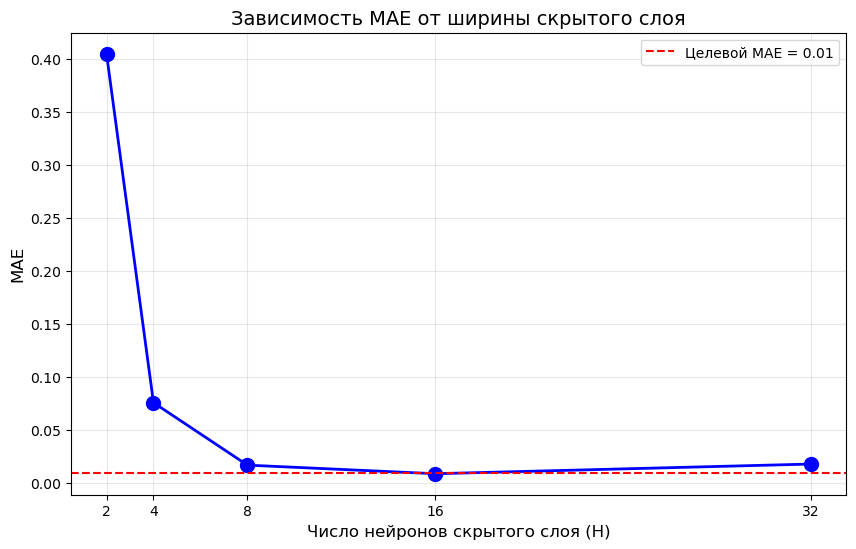

In [22]:
# График 1: Зависимость MAE от H
plt.figure(figsize=(10, 6))
h_values = []
min_mae_values = []
for H in hidden_sizes:
    h_results = [r for r in results if r['H'] == H]
    min_mae = min([r['mae'] for r in h_results])
    h_values.append(H)
    min_mae_values.append(min_mae)

plt.plot(h_values, min_mae_values, 'bo-', linewidth=2, markersize=10)
plt.xlabel('Число нейронов скрытого слоя (H)', fontsize=12)
plt.ylabel('MAE', fontsize=12)
plt.title('Зависимость MAE от ширины скрытого слоя', fontsize=14)
plt.grid(True, alpha=0.3)
plt.xticks(h_values)
plt.axhline(y=0.01, color='r', linestyle='--', label='Целевой MAE = 0.01')
plt.legend()
plt.show()

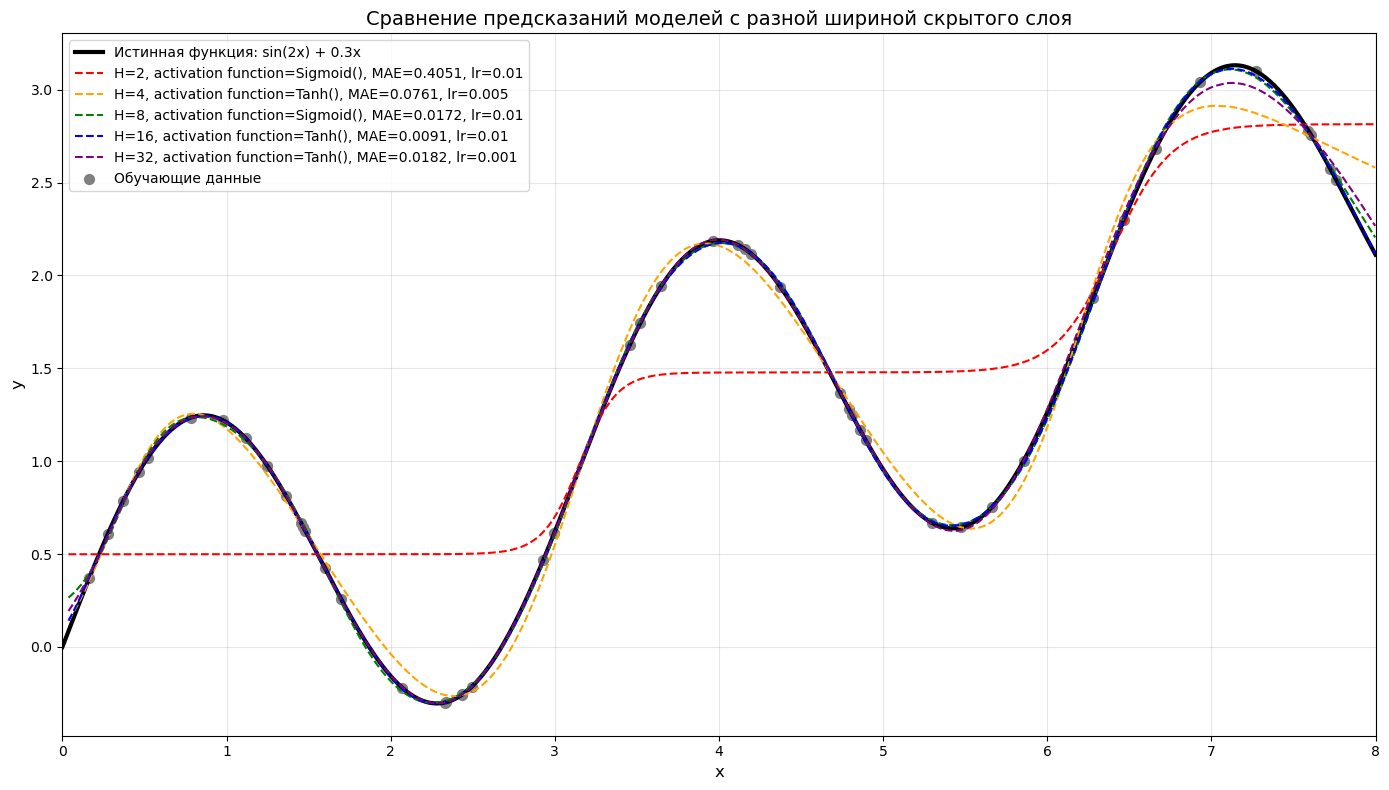

In [27]:
# График 2: Сравнение истинной функции и предсказаний для разных H
# Создаем гладкие точки для отображения функции
x_smooth = np.linspace(0, 8, 1000).reshape(-1, 1).astype(np.float32)
y_smooth = (np.sin(2 * x_smooth) + 0.3 * x_smooth).astype(np.float32)


# Вариант 1: Все модели на одном графике
plt.figure(figsize=(14, 8))

# Истинная функция
plt.plot(x_smooth, y_smooth, color='black', linewidth=3, label='Истинная функция: sin(2x) + 0.3x')

# Предсказания для разных H
colors = ['red', 'orange', 'green', 'blue', 'purple']
for i, H in enumerate(hidden_sizes):
    if H in best_models:
        # Сортируем для красивого графика
        sorted_idx = np.argsort(x_test.flatten())
        x_sorted = x_test[sorted_idx]
        y_pred_sorted = best_models[H]['y_pred'][sorted_idx]
        
        plt.plot(x_sorted, y_pred_sorted, 
                color=colors[i % len(colors)], 
                linestyle='--', 
                linewidth=1.5,
                label=f'H={H}, activation function={best_models[H]["act_fun"]}, MAE={best_models[H]["mae"]:.4f}, lr={best_models[H]['lr']}')

# Точки обучения
plt.scatter(x_train, y_train, color='gray', alpha=1, s=50, label='Обучающие данные')

plt.xlabel('x', fontsize=12)
plt.ylabel('y', fontsize=12)
plt.title('Сравнение предсказаний моделей с разной шириной скрытого слоя', fontsize=14)
plt.legend(loc='best', fontsize=10)
plt.grid(True, alpha=0.3)
plt.xlim(0, 8)
plt.tight_layout()
plt.show()

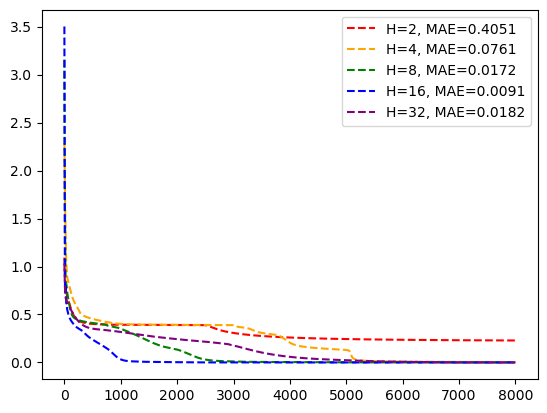

In [24]:
colors = ['red', 'orange', 'green', 'blue', 'purple']
for i, H in enumerate(hidden_sizes):
    if H in best_models:
        # Сортируем для красивого графика
        loss_history = best_models[H]['loss_history']
        
        plt.plot(loss_history, 
                color=colors[i % len(colors)], 
                linestyle='--', label=f'H={H}, MAE={best_models[H]["mae"]:.4f}')
plt.legend()

                         Скрытый слой
    Вход               (16 нейронов)              Выход
                          
                      ┌─────────────┐
                     │              │
                ┌───▶│  Нейрон 1   │───┐
                │    │   (h₁)      │   │
                │    └─────────────┘   │
                │                      │
                │    ┌─────────────┐   │
                │   │              │   │
        xᵢ ─────┼──▶│  Нейрон 2   │───┼────▶ f(xᵢ)
                │   │   (h₂)      │   │
                │   └─────────────┘   │
                │                      │
                │    ┌─────────────┐   │
                │   │              │   │
                ├──▶│  Нейрон 3   │───┤
                │   │   (h₃)      │   │
                │   └─────────────┘   │
                │          ⋮           │
                │                      │
                │   ┌─────────────┐   │
                │  │              │   │
                └──▶│  Нейрон 16  │───┘
                   │   (h₁₆)      │
                   └─────────────┘

    Вход:         Скрытый слой:        Выход:
    xᵢ ∈ ℝ        16 нейронов          f(xᵢ) ∈ ℝ
                   Активация: Tanh     Активация: Linear

In [25]:
best_h = min(best_models, key=lambda h: best_models[h]['mae'])

# Get the full dictionary entry
best_entry = best_models[best_h]

print(f"Best H: {best_h}")
print(f"Best activation function: {best_entry['act_fun']}")
print(f"Best MAE: {best_entry['mae']}")
print(f"Max MAE: {best_entry['max_mae']}")
print(f"Best LR: {best_entry['lr']}")
print(f"Число обучаемых параметров: {sum(p.numel() for p in model.parameters())}")

Best H: 16
Best activation function: Tanh()
Best MAE: 0.00905801635235548
Max MAE: 0.056159354746341705
Best LR: 0.01
Число обучаемых параметров: 97


## Контрольные вопросы

1. Почему для скрытого слоя в задаче аппроксимации предпочтительнее использовать
tanh/сигмоиду, а не ReLU?
    Они лучше подходят для гладкой аппроксимации, чем ReLU, не имеющий изгибов после первого излома

2. Почему выходной нейрон в задаче аппроксимации, как правило, не использует нелинейную функцию активации?
    Поскольку аппроксимируемые значения не ограничены диапазоном (0, 1)

3. Что произойдёт, если взять слишком мало нейронов скрытого слоя? Слишком много?
    Слишком мало нейронов – сеть не может уловить форму функции (недообучение), слишком много –
    риск переобучения на шуме (для гладких аналитических функций без шума это менее критично, чем для реальных данных, но чрезмерно большая сеть будет обучаться
    медленнее и хуже интерпретироваться).
    
4. Зачем нужна отдельная (более плотная) тестовая выборка, если функция уже известна аналитически?
    Чтобы визуально и численно оценить, насколько гладко и точно сеть воспроизводит функцию между обучающими точками, а не только в них самих.

5. Как теорема универсальной аппроксимации связана (и не связана) с практической
задачей, решаемой в этой лабораторной работе?
    Согласно теореме об универсальной аппроксимации, сеть с одним скрытым слоем достаточной ширины и нелинейной функцией активации способна приблизить любую непрерывную функцию на компактном множестве с произвольной точностью.